In [117]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_blobs, make_moons, make_circles, make_classification
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

In [118]:
import warnings
warnings.filterwarnings('ignore')
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.3
numpy: 2.1.3


In [119]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 20)

# Часть 1. EDA и Preprocessing.

In [120]:
df = pd.read_csv("german_credit_data.csv.xls")
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [121]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
dtypes: int64(5), object(5)
memory usage: 78.3+ KB


In [122]:
# Age - Возраст
# Sex - Пол
# Job - Работа
# Housсing - Жилье
# Saving accounts - Сберегательные счета
# Checking account - Расчетный счет
# Credit amount - Сумма кредита
# Duration - Срок кредита (мес)
# Purpose - Цель

In [123]:
df.shape

(1000, 10)

In [124]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [125]:
df.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0


В датасете 1000 клиентов, у 183 отсутствуют сберегательные счета и у 394 отсутствуют расчетные счета. Это не явный пропуск в датасете, поэтому закодирую как отдельную категорию "none".

In [126]:
df = df.drop(columns=['Unnamed: 0'])

df['Saving accounts'] = df['Saving accounts'].fillna('none')
df['Checking account'] = df['Checking account'].fillna('none')

df.isnull().sum()

,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,0
Checking account,0
Credit amount,0
Duration,0
Purpose,0


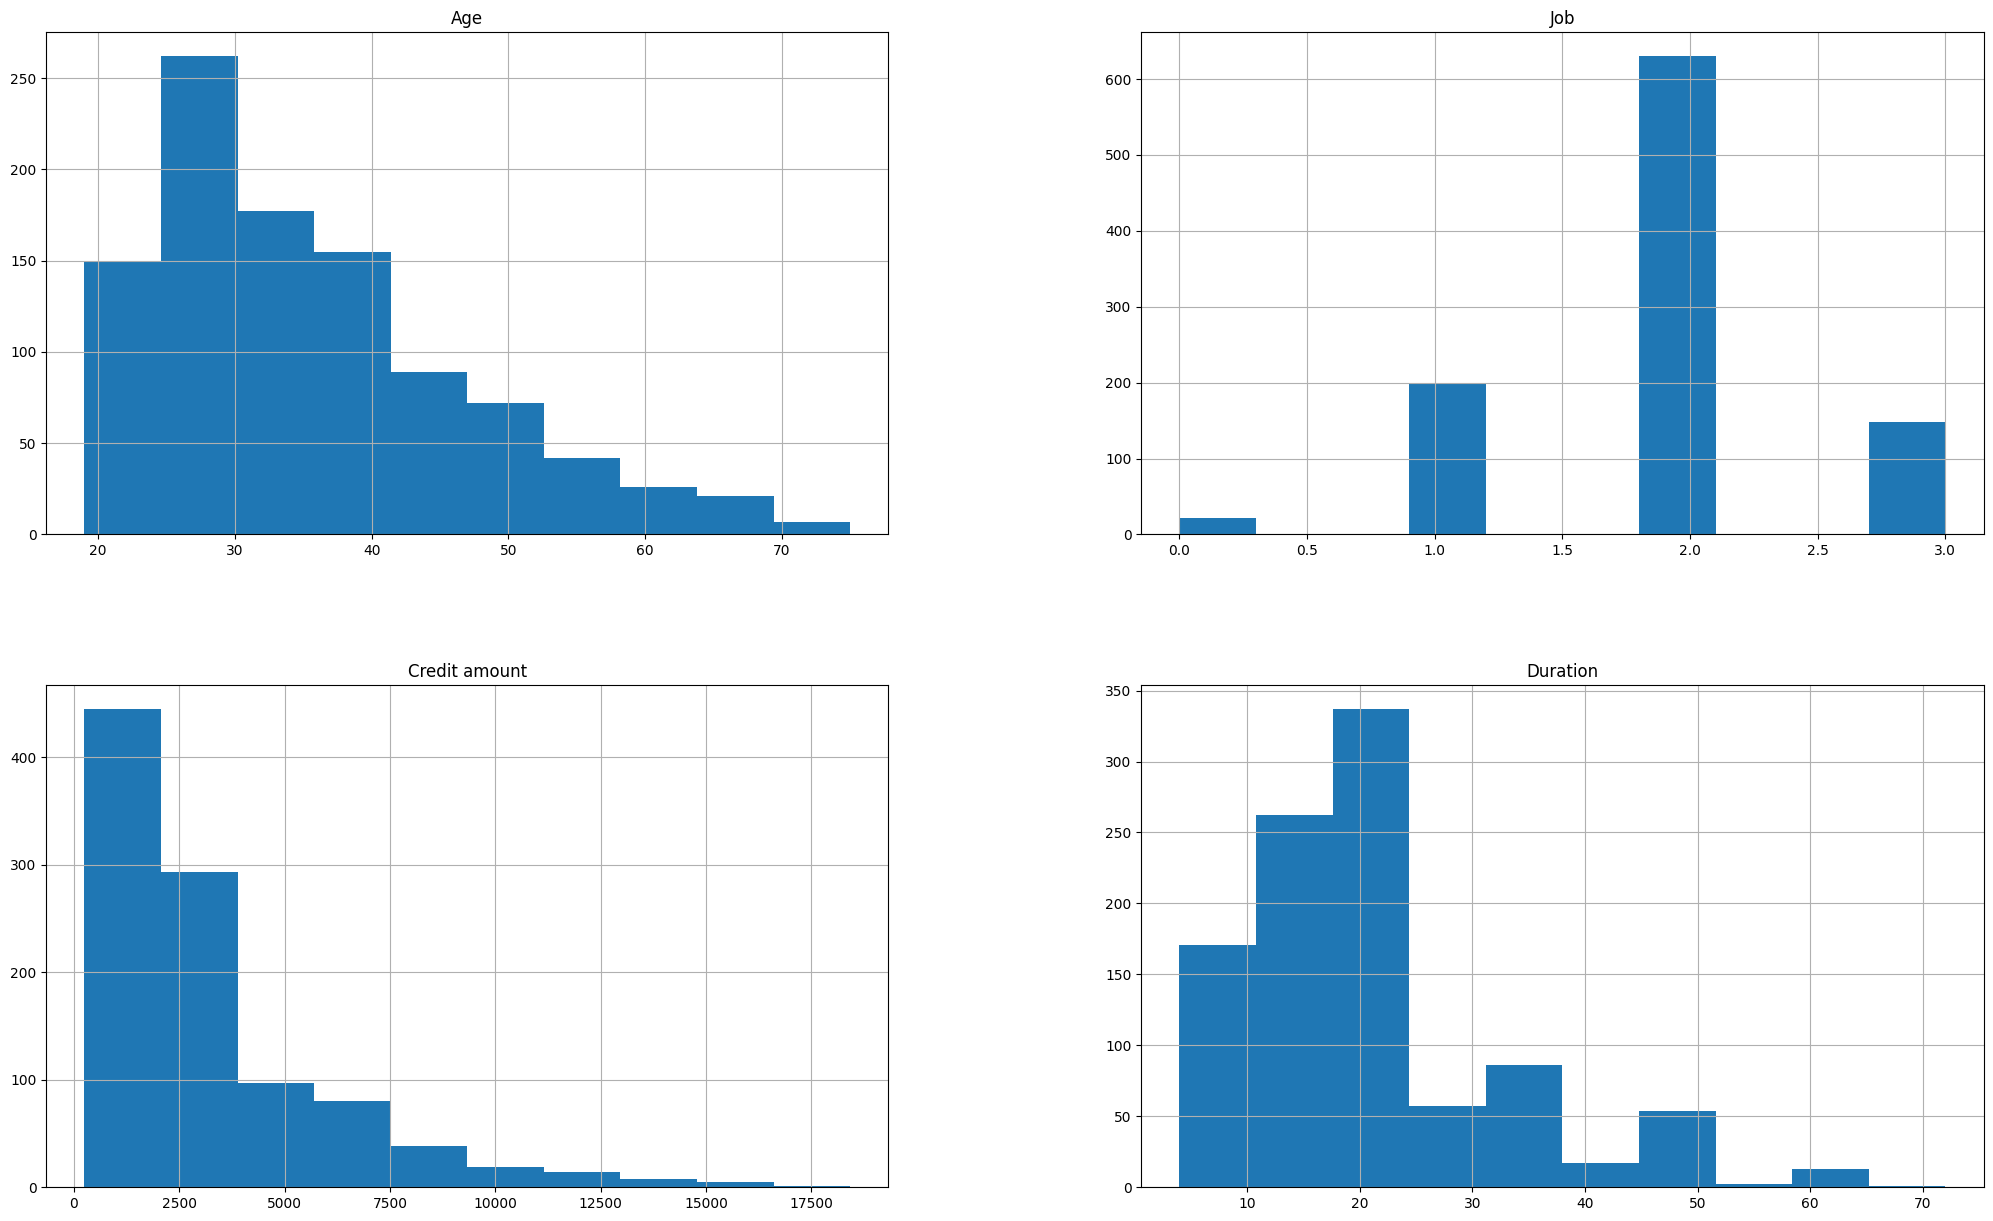

In [127]:
df.hist(figsize=(25, 15))

plt.show()

По графику увидела:
1. наибольший класс клиентов, которые взяли кредит - это клиенты в возрасте от 25 до 30 лет
2. Сумма кредита в большей части до ~2500, а максимальное значение ~ 16500
3. Большинство клиентов берут кредит сроком от 4 до 24 мес, а самый популярный срок в диапазоне от ~18 до ~24 мес

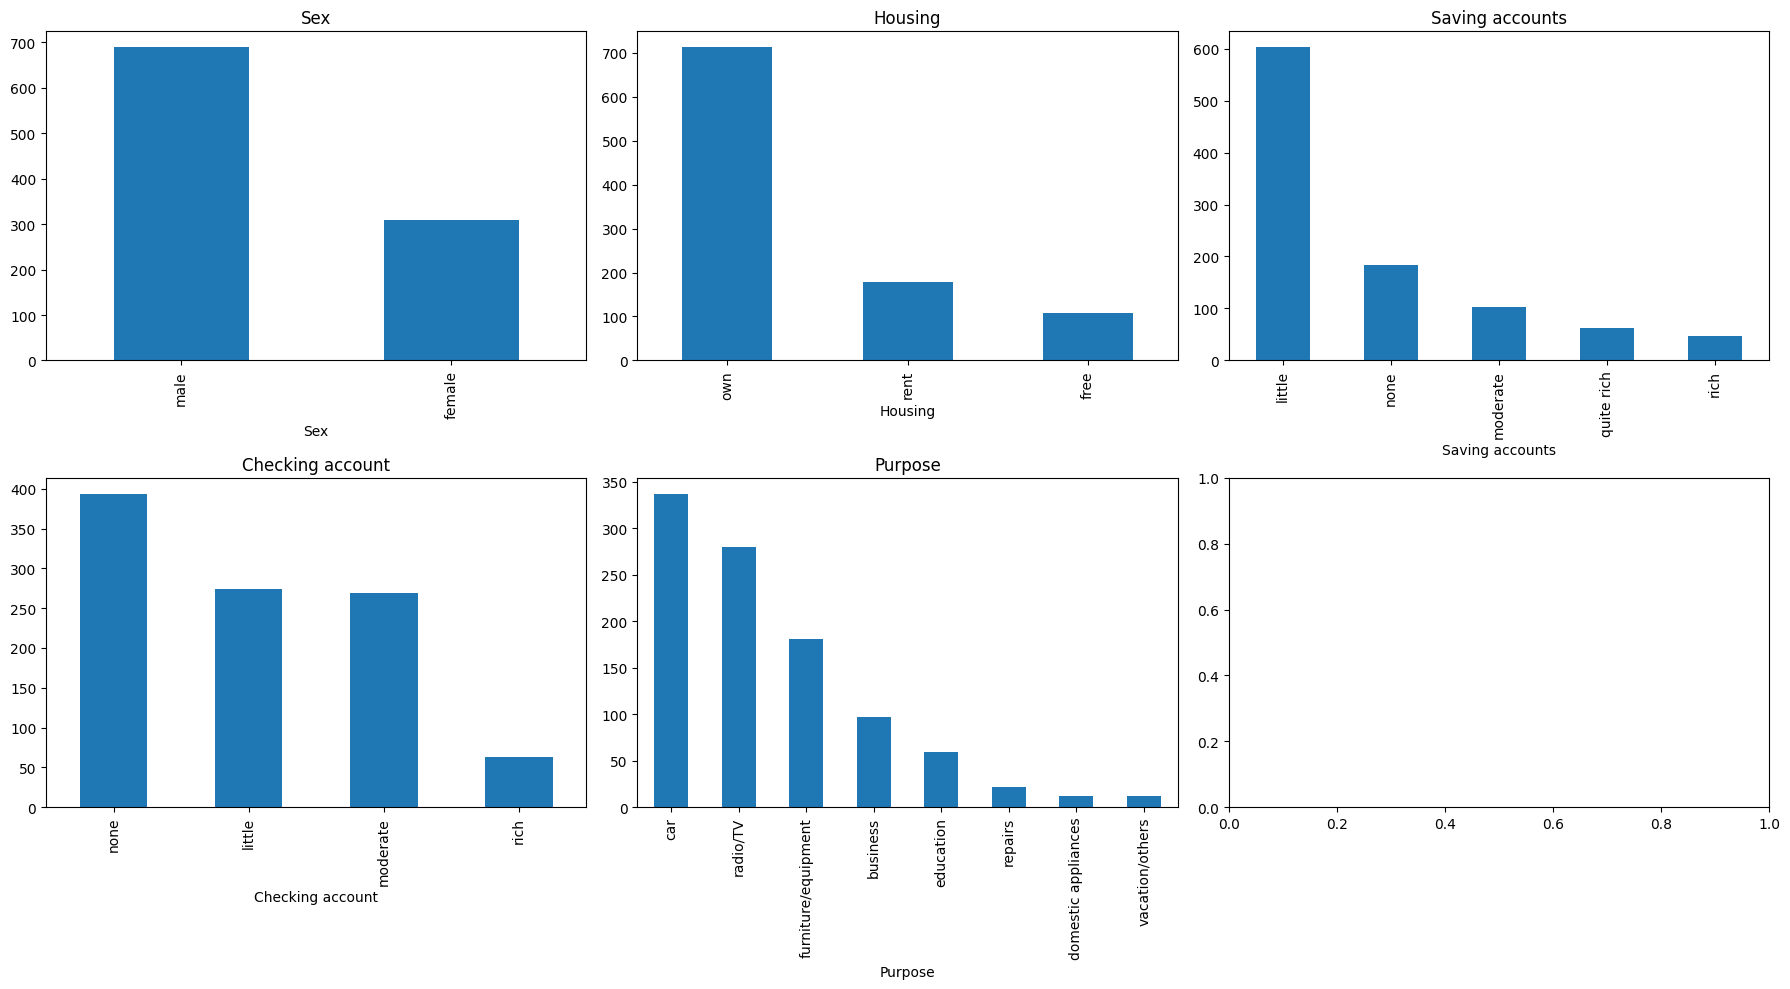

In [128]:
# Распределение категориальных признаков
cat_cols = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

По графику:
1. Чаще всего кредит берут мужчины
2. Берут кредит чаще клиенты, у которых уже есть собственное жилье
3. Люди с небольшими накоплениями чаще нуждаются в кредите
4. Самая популярная цель оформления кредита - машина, а самая редкая - отдых

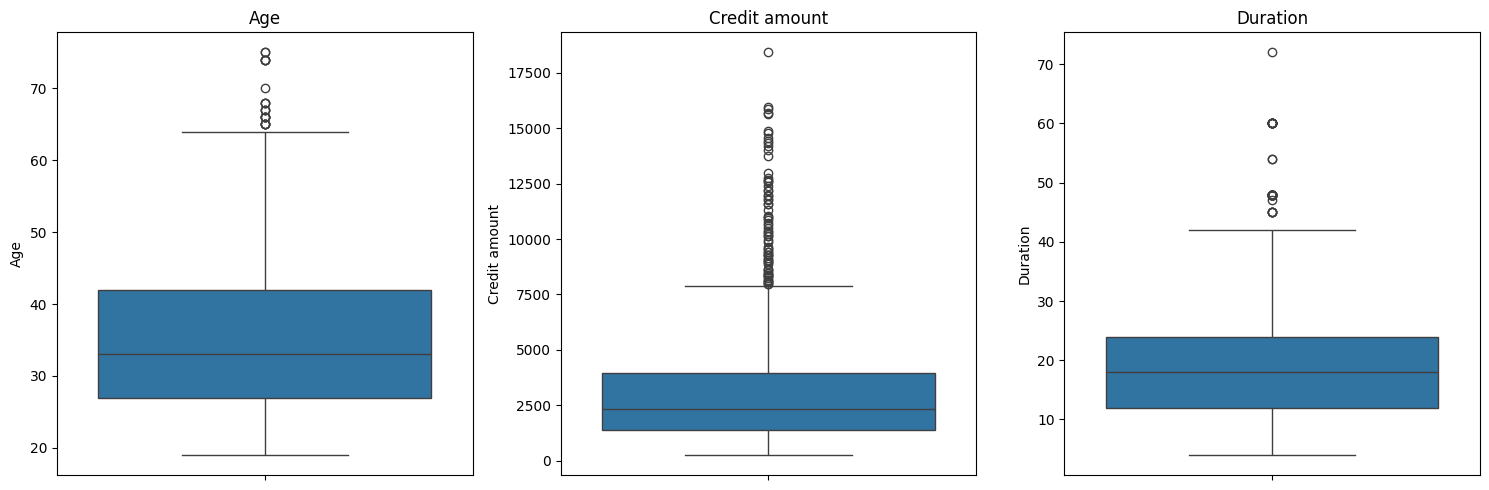

In [129]:
# Числовые признаки
num_cols = ['Age', 'Credit amount', 'Duration']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [130]:
# Считаю количество выбросов по IQR методу
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} выбросов (границы: {lower:.1f} — {upper:.1f})")

Age: 23 выбросов (границы: 4.5 — 64.5)
Credit amount: 72 выбросов (границы: -2544.6 — 7882.4)
Duration: 70 выбросов (границы: -6.0 — 42.0)


Предполагаю, что выбросы - это не лишние строки в данных, а крупные и длительные кредиты. Не буду их удалять, применю RobustScaler при масштабировании.

Часть признаков порядковые, а часть номинальные, поэтому кодировать буду по-разному:
1. Saving accounts и Checking account имеют естественный порядок, кодировать буду через OrdinalEncoder;

2. Sex, Housing, Purpose номинальные, порядка нет, кодировать буду через OneHotEncoder.

3. Job числовой (0–3), оставлю как есть

In [131]:
df['Saving accounts'].unique()

array(['none', 'little', 'quite rich', 'rich', 'moderate'], dtype=object)

In [132]:
df['Checking account'].unique()

array(['little', 'moderate', 'none', 'rich'], dtype=object)

In [133]:
from sklearn.preprocessing import OrdinalEncoder

# Ordinal Encoding для счетов
saving_order = ['none', 'little', 'moderate', 'quite rich', 'rich']
checking_order = ['none', 'little', 'moderate', 'rich']

ordinal_encoder = OrdinalEncoder(categories=[saving_order, checking_order])
df[['Saving accounts', 'Checking account']] = ordinal_encoder.fit_transform(
    df[['Saving accounts', 'Checking account']]
)

# One Hot для номинальных признаков
df_encoded = pd.get_dummies(df, columns=['Sex', 'Housing', 'Purpose'], drop_first=True)

df_encoded.head()

,Age,Job,Saving accounts,Checking account,Credit amount,Duration,Sex_male,Housing_own,Housing_rent,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,2,0.0,1.0,1169,6,True,True,False,False,False,False,False,True,False,False
1,22,2,1.0,2.0,5951,48,False,True,False,False,False,False,False,True,False,False
2,49,1,1.0,0.0,2096,12,True,True,False,False,False,True,False,False,False,False
3,45,2,1.0,1.0,7882,42,True,False,False,False,False,False,True,False,False,False
4,53,2,1.0,1.0,4870,24,True,False,False,True,False,False,False,False,False,False


In [134]:
df_encoded.dtypes

,0
Age,int64
Job,int64
Saving accounts,float64
Checking account,float64
Credit amount,int64
Duration,int64
Sex_male,bool
Housing_own,bool
Housing_rent,bool
Purpose_car,bool


Переведу bool в int

In [135]:
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

df_encoded.dtypes

,0
Age,int64
Job,int64
Saving accounts,float64
Checking account,float64
Credit amount,int64
Duration,int64
Sex_male,int64
Housing_own,int64
Housing_rent,int64
Purpose_car,int64


In [136]:
# Масштабирование
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_scaled = scaler.fit_transform(df_encoded)
X_scaled = pd.DataFrame(X_scaled, columns=df_encoded.columns)

X_scaled.head()

,Age,Job,Saving accounts,Checking account,Credit amount,Duration,Sex_male,Housing_own,Housing_rent,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,2.266667,0.0,-1.0,0.0,-0.441354,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.733333,0.0,0.0,0.5,1.393114,2.5,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1.066667,-1.0,0.0,-0.5,-0.085739,-0.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.800000,0.0,0.0,0.0,2.133883,2.0,0.0,-1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1.333333,0.0,0.0,0.0,0.978421,0.5,0.0,-1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


**"Почему масштабирование необходимо при кластеризации?"**

Все три алгоритма (KMeans, hierarchical, DBSCAN) опираются на расстояние между точками. Если признаки в разных единицах и диапазонах (Credit amount от 250 до 18000, Saving accounts от 0 до 4), то после кодирования признаки с большими разбросами будут доминировать в расстоянии между точками просто из-за масштаба, а не из-за важности. В результате алгоритм может игнорировать важные признаки. Приведение всех признаков к одному масштабу уравняет их вклад в расстояние и не будет выделять крупные значения как выбросы.

# Часть 2. Моделирование.

100%|██████████| 9/9 [00:00<00:00, 10.76it/s]


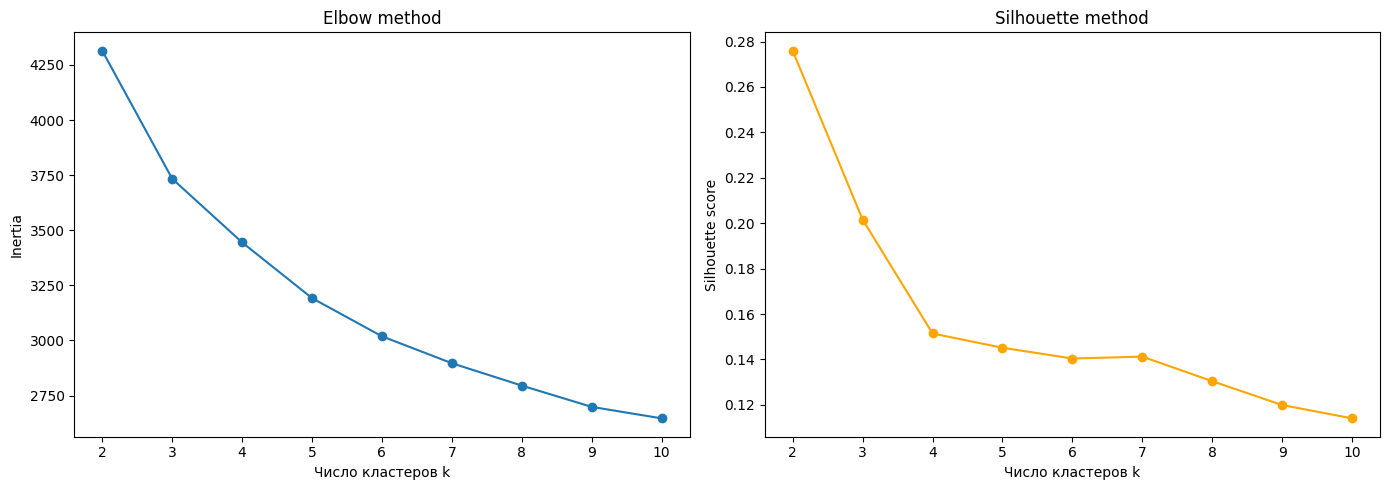

In [137]:
# Подбор оптимального k для KMeans
from sklearn.cluster import KMeans

inertia = []
silhouette = []
k_range = range(2, 11)

for k in tqdm(k_range):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

# Elbow method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia, marker='o')
axes[0].set_xlabel('Число кластеров k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(k_range, silhouette, marker='o', color='orange')
axes[1].set_xlabel('Число кластеров k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette method')

plt.tight_layout()
plt.show()

По графикам:
1. Elbow method - явного перелома нет, линия плавная
2. Silhouette method - максимум при k=2 ~0.28, далее значение резко падает и на k=4 становится почти в два раза меньше ~0.15, а далее держится в диапазоне от ~0.12 до ~0.15

In [138]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans_2 = kmeans_2.fit_predict(X_scaled)

kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_kmeans_4 = kmeans_4.fit_predict(X_scaled)

print("k=2:", pd.Series(labels_kmeans_2).value_counts().to_dict())
print("k=4:", pd.Series(labels_kmeans_4).value_counts().to_dict())

k=2: {1: 786, 0: 214}
k=4: {1: 481, 3: 235, 2: 178, 0: 106}


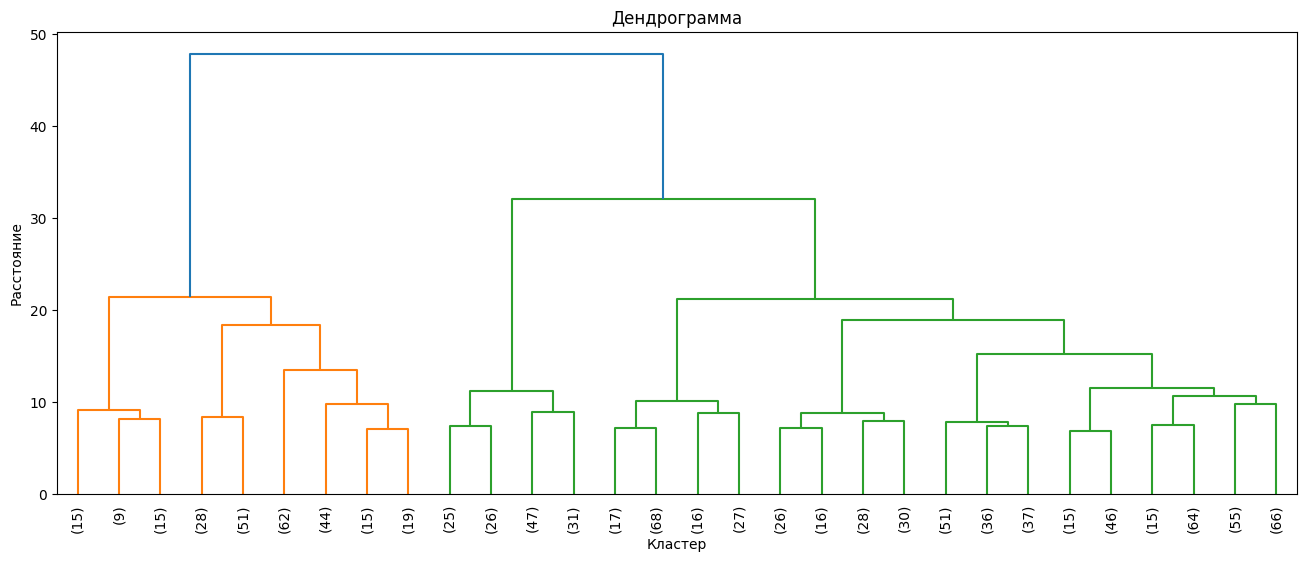

In [139]:
# Linkage matrix
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(16, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Дендрограмма')
plt.xlabel('Кластер')
plt.ylabel('Расстояние')
plt.show()

Первый шаг ~48 — это разделение всех данных на 2 кластера: оранжевую ветвь и зелёную. Это соответствует тому, что получила в silhouette method для KMeans (k=2). Явного разрыва по высоте визуально не видно, переходы между уровнями плавные, вероятно, кластеры в данных не очень чётко разделены.
Считаю данные для разных вариантов разреза:

k=2: silhouette=0.2298, размеры кластеров={2: 742, 1: 258}
k=3: silhouette=0.1882, размеры кластеров={3: 613, 1: 258, 2: 129}
k=4: silhouette=0.1713, размеры кластеров={4: 613, 2: 219, 3: 129, 1: 39}
k=5: silhouette=0.1264, размеры кластеров={5: 485, 2: 219, 3: 129, 4: 128, 1: 39}
k=6: silhouette=0.1167, размеры кластеров={6: 385, 2: 219, 3: 129, 4: 128, 5: 100, 1: 39}


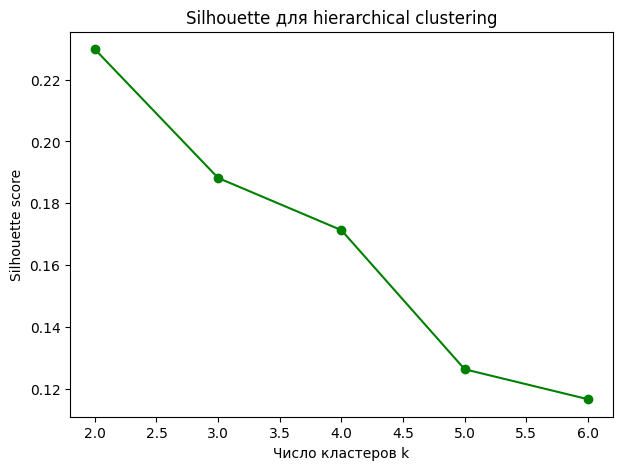

In [140]:
silhouette_hierarchical = []
k_range_h = range(2, 7)

for k in k_range_h:
    labels_h = fcluster(Z, t=k, criterion='maxclust')
    score = silhouette_score(X_scaled, labels_h)
    silhouette_hierarchical.append(score)
    print(f"k={k}: silhouette={score:.4f}, размеры кластеров={pd.Series(labels_h).value_counts().to_dict()}")

plt.figure(figsize=(7, 5))
plt.plot(k_range_h, silhouette_hierarchical, marker='o', color='green')
plt.xlabel('Число кластеров k')
plt.ylabel('Silhouette score')
plt.title('Silhouette для hierarchical clustering')
plt.show()

Лучший по метрике оказался k = 2 и k = 4. Elbow method не показывает ярко выраженного локтя, поэтому разделение на 2 кластера буду рассматривать как наиболее подходящее

In [141]:
labels_hier_2 = fcluster(Z, t=2, criterion='maxclust')
labels_hier_4 = fcluster(Z, t=4, criterion='maxclust')

## DBSCAN

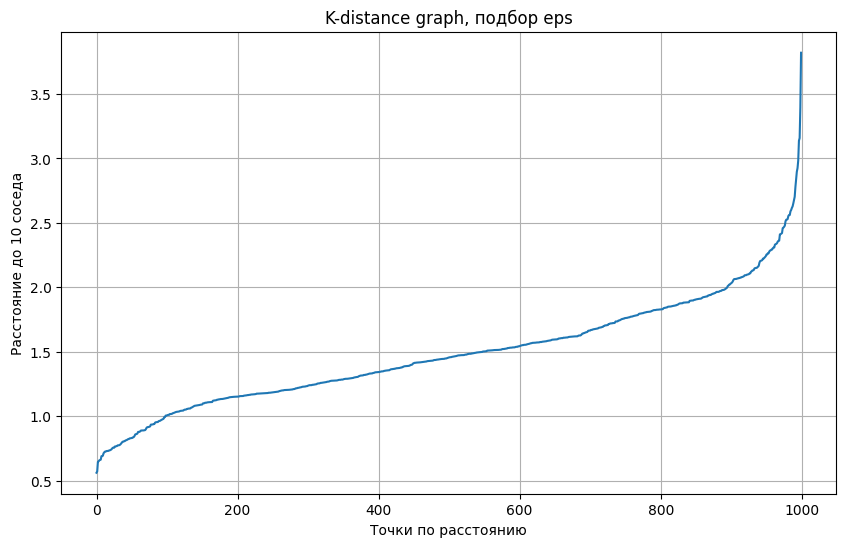

In [142]:
min_samples = 10

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Беру расстояние до k соседа и сортирую по возрастанию
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(k_distances)
plt.xlabel('Точки по расстоянию')
plt.ylabel(f'Расстояние до {min_samples} соседа')
plt.title('K-distance graph, подбор eps')
plt.grid(True)
plt.show()

Основной подъем начинается примерно после 900 точки на расстоянии от ~2.0 до 2.2. До этого кривая растёт плавно и постепенно, а после 950 точки вертикально вверх до ~ 3.7/3.8.
Возьму eps ≈ 2.0/2.2 как стартовую точку.

In [143]:
from sklearn.cluster import DBSCAN

eps_values = [1.8, 2.0, 2.2, 2.4, 2.6]
min_samples = 10

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels_db = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    n_noise = list(labels_db).count(-1)

    if n_clusters > 1:
        mask = labels_db != -1
        score = silhouette_score(X_scaled[mask], labels_db[mask])
    else:
        score = None

    print(f"eps={eps}: кластеров={n_clusters}, шум={n_noise} ({n_noise/len(labels_db)*100:.1f}%), silhouette={score}")

eps=1.8: кластеров=1, шум=71 (7.1%), silhouette=None
eps=2.0: кластеров=1, шум=26 (2.6%), silhouette=None
eps=2.2: кластеров=1, шум=15 (1.5%), silhouette=None
eps=2.4: кластеров=1, шум=5 (0.5%), silhouette=None
eps=2.6: кластеров=1, шум=3 (0.3%), silhouette=None


При всех значениях eps от 1.8 до 2.6 получаю только 1 кластер с разным количеством шума. Это значит, что выбранный диапазон eps слишком большой и почти все точки попадают в одну плотную область, DBSCAN не видит разделения на группы.

In [144]:
# Уменьшаю eps
eps_values = [1.0, 1.2, 1.4, 1.5, 1.6, 1.7]
min_samples = 10

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels_db = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    n_noise = list(labels_db).count(-1)

    if n_clusters > 1:
        mask = labels_db != -1
        score = silhouette_score(X_scaled[mask], labels_db[mask])
    else:
        score = None

    print(f"eps={eps}: кластеров={n_clusters}, шум={n_noise} ({n_noise/len(labels_db)*100:.1f}%), silhouette={score}")

eps=1.0: кластеров=10, шум=810 (81.0%), silhouette=0.32470518153464106
eps=1.2: кластеров=4, шум=492 (49.2%), silhouette=0.08820115307587374
eps=1.4: кластеров=2, шум=314 (31.4%), silhouette=0.2976713538943159
eps=1.5: кластеров=1, шум=241 (24.1%), silhouette=None
eps=1.6: кластеров=1, шум=158 (15.8%), silhouette=None
eps=1.7: кластеров=1, шум=107 (10.7%), silhouette=None


Результат:
1. eps=1.0 даёт самый высокий silhouette (0.3247), при этом 81% точек шум.  То есть модель нашла 10 кластеров, а почти все остальные точки не смогла никуда отнести. Результат неинформативный.
2. eps=1.2 даёт 4 кластера, но с низким silhouette (0.088). Кластеры плохо разделены, почти половина точек в шуме.
3. eps=1.4 — 2 кластера, 31% шума, silhouette 0.2977. silhouette почти такой же, как у k-means/hierarchical при 2 кластерах
4. При eps от 1.5 всё попадает в один кластер.

Проверила также диапазон eps 0.7–0.9 (Первый подъём на графике) — доля шума получилась ещё выше, кластеры меньше и шум до 96,4 %.

# Вывод:
Для данного датасета KMeans и  hierarchial clustering  дают более удобную для интерпретации сегментацию. Наиболее содержательный результат eps=1.4, min_samples=10 (2 кластера, 31.4% шума, silhouette~0.30), но большая часть клиентов классифицируется как выбросы, что некорректно.

Причина, вероятно, из-за множества столбцов после One Hot, из-за которой DBSCAN не может найти чёткие плотные области.

Оптимальное число кластеров для KMeans k=2, поскольку при этом достигается максимальное значение Silhouette Score. Elbow method не показывает выраженного перелома, поэтому основным критерием выбора является Silhouette Score. Вариант k=4 можно рассматривать как дополнительную более детальную сегментацию, но он имеет более низкое качество разделения

## PCA, t-SNE, UMAP

In [145]:
# PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA {pca.explained_variance_ratio_.sum()*100:.1f}% дисперсии 2 компонентами")

# t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

PCA 49.5% дисперсии 2 компонентами


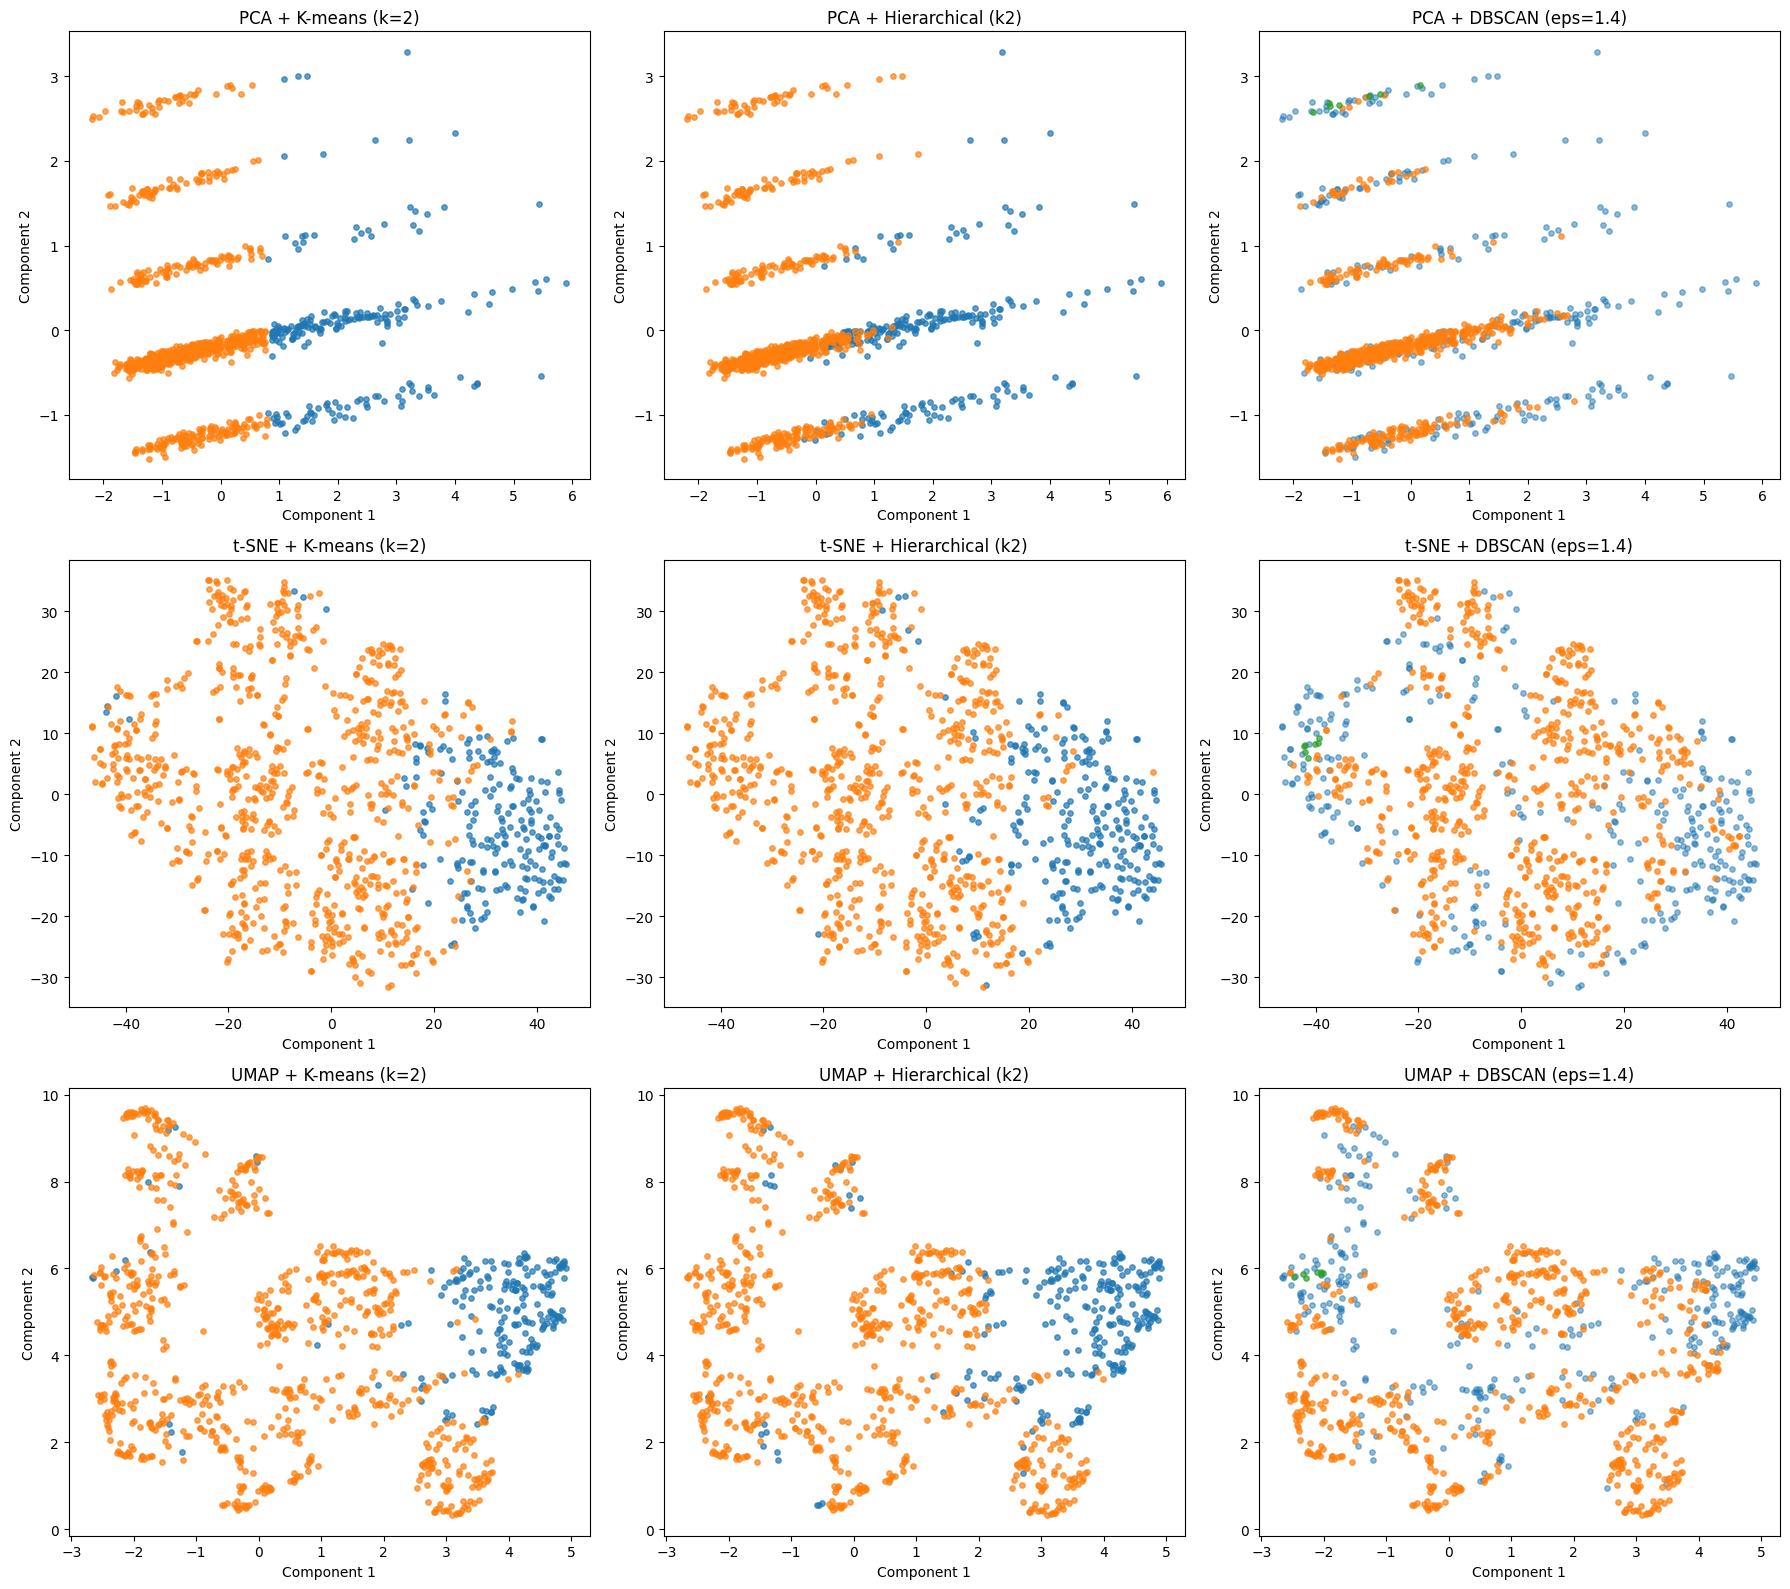

In [146]:
def plot_clusters(X_2d, labels, ax, title):
    unique_labels = sorted(set(labels))

    for label in unique_labels:
        mask = labels == label

        if label == -1:
            ax.scatter(
                X_2d[mask, 0],
                X_2d[mask, 1],
                s=15,
                alpha=0.5,
                label='Noise'
            )
        else:
            ax.scatter(
                X_2d[mask, 0],
                X_2d[mask, 1],
                s=15,
                alpha=0.7,
                label=f'Cluster {label}'
            )

    ax.set_title(title)
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')

projections = {'PCA': X_pca, 't-SNE': X_tsne, 'UMAP': X_umap}
clusterings = {
    'K-means (k=2)': labels_kmeans_2,
    'Hierarchical (k2)': labels_hier_2,
    'DBSCAN (eps=1.4)': DBSCAN(eps=1.4, min_samples=10).fit_predict(X_scaled)
}

fig, axes = plt.subplots(3, 3, figsize=(18, 16))

for row, (proj_name, X_2d) in enumerate(projections.items()):
    for col, (clust_name, labels) in enumerate(clusterings.items()):
        plot_clusters(X_2d, labels, axes[row, col], f'{proj_name} + {clust_name}')

plt.tight_layout()
plt.show()

Поссмотрю то же самое для k = 4

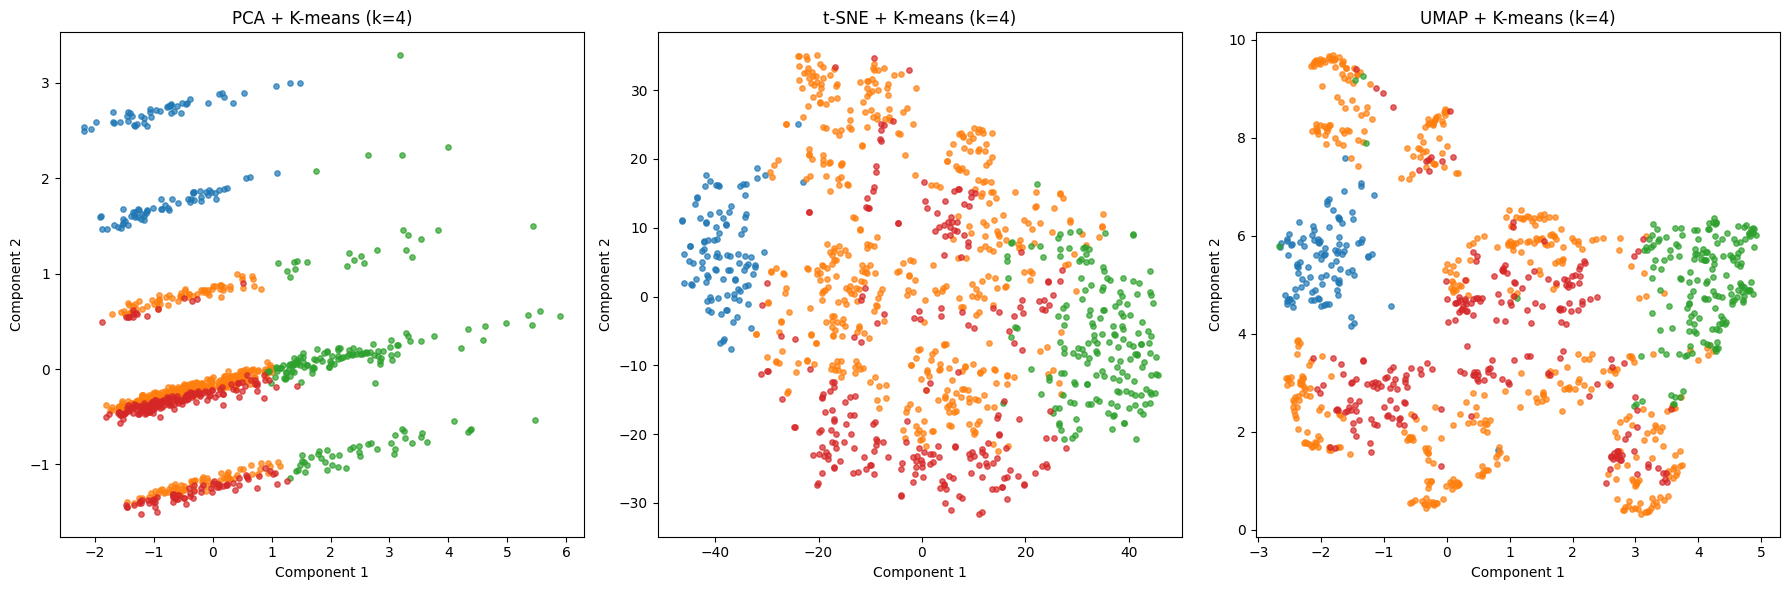

In [147]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (proj_name, X_2d) in zip(axes, projections.items()):
    plot_clusters(X_2d, labels_kmeans_4, ax, f'{proj_name} + K-means (k=4)')

plt.tight_layout()
plt.show()

Во всех трёх проекциях отделяется только один кластер (синий), что подтверждает, что данные делятся на особую группу, а не на 4 естественных обособленных кластера. Диагональная структура на PCA говорит о том, что разбиение градиента произвольное.

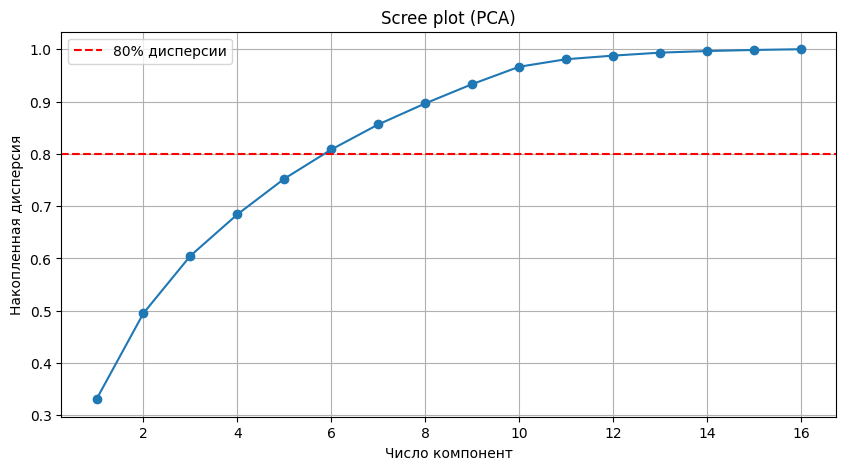

Компонент для 80% дисперсии: 6


In [148]:
pca_full = PCA(random_state=42).fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = explained.cumsum()

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumulative)+1), cumulative, marker='o')
plt.axhline(y=0.8, color='r', linestyle='--', label='80% дисперсии')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная дисперсия')
plt.title('Scree plot (PCA)')
plt.legend()
plt.grid(True)
plt.show()

print(f"Компонент для 80% дисперсии: {(cumulative < 0.8).sum() + 1}")

In [149]:
df_interpret = df_encoded.copy()
df_interpret['cluster'] = labels_kmeans_2

cluster_means = df_interpret.groupby('cluster').mean()
cluster_means

,Age,Job,Saving accounts,Checking account,Credit amount,Duration,Sex_male,Housing_own,Housing_rent,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
cluster,,,,,,,,,,,,,,,,
0,36.098131,2.228972,0.934579,1.046729,7435.415888,37.462617,0.771028,0.635514,0.135514,0.411215,0.009346,0.060748,0.112150,0.191589,0.018692,0.037383
1,35.395674,1.815522,1.259542,0.988550,2137.505089,16.394402,0.667939,0.734097,0.190840,0.316794,0.012723,0.058524,0.199746,0.304071,0.022901,0.005089


In [150]:
df_interpret = df_encoded.copy()
df_interpret['cluster'] = labels_kmeans_4

cluster_means = df_interpret.groupby('cluster').mean()
cluster_means

,Age,Job,Saving accounts,Checking account,Credit amount,Duration,Sex_male,Housing_own,Housing_rent,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
cluster,,,,,,,,,,,,,,,,
0,37.084906,1.811321,3.443396,0.764151,2223.518868,17.452830,0.688679,0.735849,0.198113,0.320755,0.018868,0.047170,0.207547,0.283019,0.028302,0.000000
1,28.758836,1.889813,0.993763,1.051975,2271.043659,17.715177,0.619543,0.717256,0.234927,0.293139,0.016632,0.047817,0.222453,0.305613,0.020790,0.002079
2,35.567416,2.247191,0.921348,1.084270,7924.342697,39.140449,0.775281,0.623596,0.134831,0.421348,0.005618,0.061798,0.101124,0.191011,0.005618,0.044944
3,48.727660,1.714894,0.778723,0.940426,2266.638298,15.170213,0.770213,0.761702,0.089362,0.370213,0.004255,0.085106,0.144681,0.293617,0.034043,0.012766


Проверяю, как k=4 разбиение соотносится с k=2

In [151]:
pd.crosstab(labels_kmeans_2, labels_kmeans_4)

col_0,0,1,2,3
row_0,,,,
0,4,20,178,12
1,102,461,0,223


In [152]:
ct = pd.crosstab(labels_kmeans_2, labels_kmeans_4)
ct_pct = pd.crosstab(labels_kmeans_2, labels_kmeans_4, normalize='index') * 100

print('Количество клиентов (строки k=2, столбцы k=4):')
print(ct)
print()
print('Доля, % от размера каждого k=2 кластера, которая попала в каждый k=4 кластер:')
print(ct_pct.round(1))
print()

for k2_label in ct_pct.index:
    row = ct_pct.loc[k2_label]
    best_k4_label = row.idxmax()
    best_pct = row.max()
    size_k2 = ct.loc[k2_label].sum()
    count_overlap = ct.loc[k2_label, best_k4_label]
    print(f"k=2 кластер {k2_label} (всего {size_k2} чел.): "
          f"{best_pct:.1f}% ({count_overlap} чел.) совпадает с k=4 кластером {best_k4_label}")

Количество клиентов (строки k=2, столбцы k=4):
col_0    0    1    2    3
row_0                    
0        4   20  178   12
1      102  461    0  223

Доля, % от размера каждого k=2 кластера, которая попала в каждый k=4 кластер:
col_0     0     1     2     3
row_0                        
0       1.9   9.3  83.2   5.6
1      13.0  58.7   0.0  28.4

k=2 кластер 0 (всего 214 чел.): 83.2% (178 чел.) совпадает с k=4 кластером 2
k=2 кластер 1 (всего 786 чел.): 58.7% (461 чел.) совпадает с k=4 кластером 1


**Итог**: Оставляю k=2, так как 83% совпало с k=4

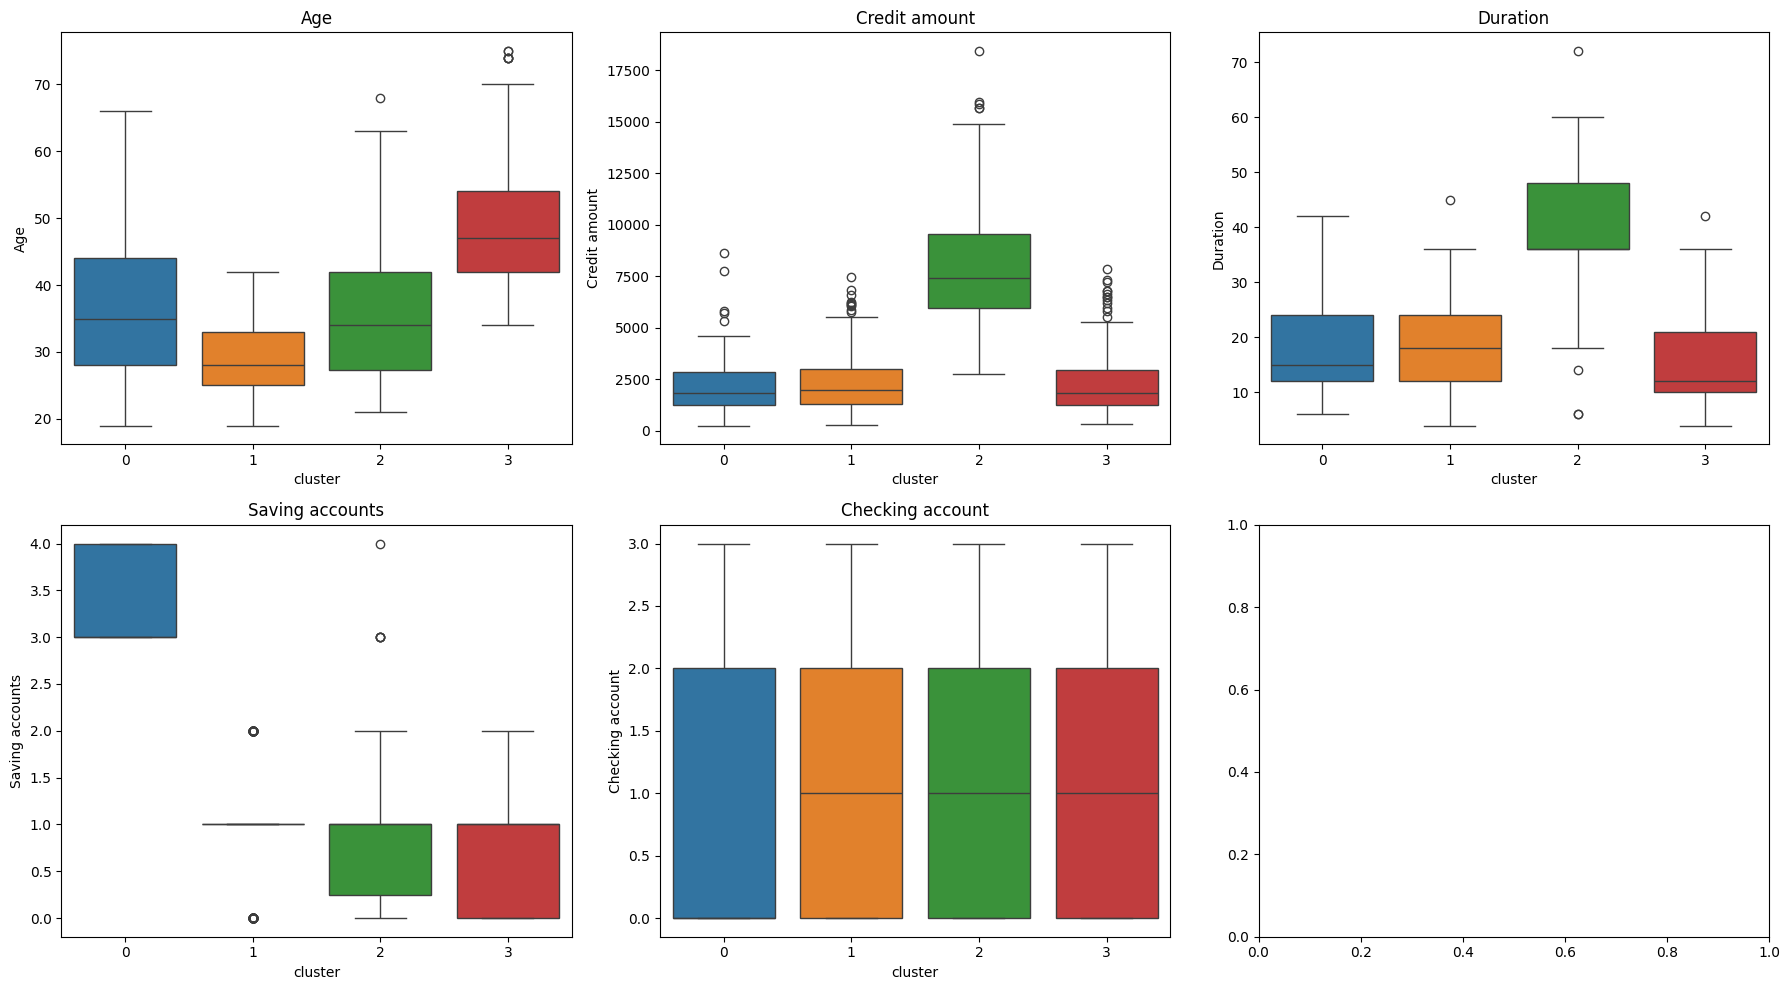

In [153]:
key_features = ['Age', 'Credit amount', 'Duration', 'Saving accounts', 'Checking account']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(data=df_interpret, x='cluster', y=col, ax=ax, palette='tab10')
    ax.set_title(col)
plt.tight_layout()
plt.show()

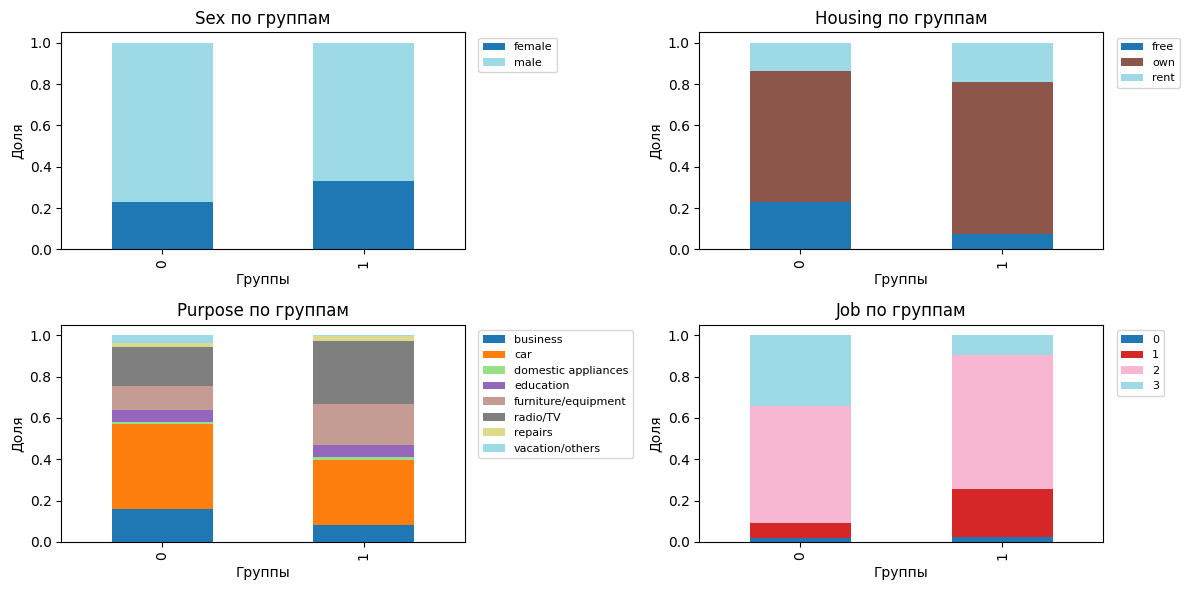

In [154]:
cat_features = ['Sex', 'Housing', 'Purpose', 'Job']

df_cat = df.copy()
df_cat['cluster'] = labels_kmeans_2

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, col in zip(axes.flatten(), cat_features):
    ct = pd.crosstab(df_cat['cluster'], df_cat[col], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
    ax.set_title(f'{col} по группам')
    ax.set_ylabel('Доля')
    ax.set_xlabel('Группы')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Вывод**: только Credit amount и Duration можно интерпретировать как признаки, которые создают кластеры. Остальные признаки (Age, checking acccount) отличаются между кластерами несильно, поэтому их можно рассматривать только как второстепенные, а не как основные.

**Итог**:
Сделала три способа кластеризации.
- KMeans и hierarchical clustering дали одинаковый результат. По метрике silhouette лучше всего делить клиентов на 2 группы, при этом чёткого локтя на elbow графике не было.
- DBSCAN не смог найти четкие кластеры.  Получался либо один кластер, либо всё уходило в шум. Основная причина, на мой взгляд, в том, что после OneHot кодирования получилось много столбцов и DBSCAN плохо различил их между собой.
- Для наглядности сжала данные тремя способами: PCA, tSNE и UMAP и рассмотрела, как на них выглядят разные варианты кластеризации. Получила такой же результат, границы между кластерами размыты и чёткого разделения нет.
- Для интерпретации взяла разбиение на 2 кластера, а не 4, так как при проверке через crosstab выяснилось, что кластер при k=4 на 83% совпадает с одним из кластеров k=2.